In [1]:
# Import the relevant libraries
import numpy as np
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import cmasher as cmr
import sympy as sp
from scipy import optimize
from numpy import sqrt
from matplotlib import rc

In [2]:
class DiagnosticDiagram:

    def __init__(self, kx, ky, omega, wac, cs, g, N, H, gamma, tau, B, epsilon, rho0, dz):

        # Assign attributes
        self.kx = kx  # km^-1
        self.ky = ky  # km^-1
        self.omega = omega  # rad/s
        self.wac = wac  # rad/s
        self.cs  = cs  # km/s 
        self.g = g  # km/s^2
        self.N = N  # rad/s
        self.H = H  # km
        self.gamma = gamma  # adiabatic index
        self.tau = tau  # s
        self.B = B  # Gauss                         
        self.epsilon = epsilon
        self.rho0 = rho0  # g/cm^3
        self.dz = dz  # km

        # Calculate the Alfven speed
        self.c_alf = (B/np.sqrt(4*np.pi*rho0))*1e-5  # km/s
        print('The Alfven speed is: ', self.c_alf, 'km/s')

        # Define the horizontal wavenumber
        self.kh = np.sqrt(self.kx**2 + self.ky**2)

        # Create meshgrids for calculations
        self.kh_grid, self.omega_grid = np.meshgrid(self.kh, self.omega) # km^-1, rad/s
        self.nu_grid = self.omega_grid/(2*np.pi)  # Hz

        # Create meshgrids for plotting
        self.kh_plot = self.kh_grid*1e3  # Mm^-1
        self.nu_plot = (self.omega_grid/(2*np.pi))*1e3  # mHz

    # Define methods
    def fmode_dispersion(self):

        '''
        Purpose
        -------
        Calculate the theoretical frequency of the f-mode as a function of wavenumber (k).

        Inputs
        ------
        None

        Outputs
        -------
        nu: np.array, float:
            Theoretical frequency for input wavenumber.

        Author(s)
        ---------
        Julio M. Morales, August 30, 2022
        '''

        # Calculate omega
        omega = np.sqrt(self.g*np.array(self.kh))

        # Turn angular frequency to temporal
        nu = omega/(2*np.pi)

        return nu
    
    def dispersion(self, omega, kh, model, solution=None):

        ''' 
        Purpose
        -------
        Calculate the dispersion relation for the internal gravity waves.

        Inputs
        ------
        kh: np.array, float:
            Horizontal wavenumber (km^-1)

        omega: np.array, float:
            Angular frequency (rad/s)

        model: str:
            Model to be used for the dispersion relation. Options are 'mt1981', 'sf1966', 'mt1982', 'bunte1993', 'nc2009', and 'vj2017'.

        Opt.
        Inputs
        -------
        solution: str
            Solution to be calculated. Options are 'real' or 'imag'.

        Outputs
        -------
        kz_sqr: np.array, float:
            Theoretical dispersion relation for input parameters.   

        Author(s)
        ---------
        Julio M. Morales, July 10th, 2024
        '''

        # Choose model
        if (model == 'mt1981'):

            # Calculate kz on the grids
            kz_sqr = pow(self.N, 2)*pow(kh, 2)/pow(omega, 2) + pow(omega, 2)/pow(self.cs, 2) -1/(4*pow(self.H, 2)) - pow(kh, 2)

        if (model == 'sf1966'):

            # Calculate kz on the grids
            kz_sqr = (pow(omega, 2) - pow(self.wac, 2))/pow(self.cs, 2) - (pow(omega, 2) - pow(self.N, 2))*pow(kh, 2)/pow(omega, 2)

        if (model == 'mt1982'):
            
            # Define parameterizations
            eta = omega*self.tau
            h0 = pow(self.N, 2)*pow(kh, 2)/pow(omega, 2) + pow(omega, 2)/pow(self.cs, 2) -1/(4*pow(self.H, 2)) - pow(kh, 2)
            a = h0 + (1 + pow(eta, 2))**(-1) * ((self.gamma - 1)*pow(omega, 2)/pow(self.cs, 2) - (pow(self.N, 2)*pow(kh, 2)/pow(omega, 2)))
            b = eta*(1 + pow(eta, 2))**(-1) * ((self.gamma - 1)*pow(omega, 2)/pow(self.cs, 2) - (pow(self.N, 2)*pow(kh, 2)/pow(omega, 2)))

            # Define the equations to be solved
            if solution == 'real':
                kz_real_sqr = 0.5*(pow(a, 2) + (pow(a, 2) + pow(b, 2))**(1/2))
                kz_sqr = kz_real_sqr
                
            if solution == 'imag':
                kz_imag_sqr = 0.5*(-pow(a, 2) + (pow(a, 2) + pow(b, 2))**(1/2))
                kz_sqr = kz_imag_sqr

        if (model == 'bunte1993'):
        
            # Choose epsilon case
            if (self.epsilon == 0.0) and (self.B == 0.0):  # Non-magnetic, non-adiabatic case

                # Define parameterizations
                hr = ((pow(omega, 2) - pow(self.wac, 2)) / self.cs**2) + kh**2*((pow(self.N, 2)/pow(omega, 2)) - 1) - (1/(1 + (omega*self.tau*self.gamma)**2))*(pow(kh, 2) - (pow(omega, 4)/pow(self.g, 2)))*(pow(self.N, 2)/pow(omega, 2))
                hi = - (omega*self.tau*self.gamma/(1 + (omega*self.tau*self.gamma)**2))*(pow(kh, 2) - (pow(omega, 4)/pow(self.g, 2)))*(pow(self.N, 2)/pow(omega, 2))

            if ((self.epsilon == 0.0) and (self.B != 0.0)):  # Exponentially decaying magnetic, non-adiabatic case

                # Define parameterizations
                p1 = (self.cs**2 + self.c_alf**2)*omega**2 - self.cs**2*self.c_alf**2*kh**2
                p_gamma = (self.cs**2 + self.gamma*self.c_alf**2)*omega**2 - self.cs**2*self.c_alf**2*kh**2
                g1 = omega**4 + self.g**2*((self.cs**2/(self.g*self.H)) - 1)*kh**2
                g_gamma = self.gamma*omega**4 + self.gamma*self.g**2*((self.cs**2/(self.gamma*self.g*self.H)) - 1)*kh**2
                hr = -(1/(4*self.H**2)) - kh**2 + (p_gamma*g_gamma + (omega*self.tau*self.gamma)**2*p1*g1) / (p_gamma**2 + (omega*self.tau*self.gamma)**2*p1**2)
                hi = (omega*self.tau*self.gamma)*(p1*g_gamma - p_gamma*g1)/(p_gamma**2 + (omega*self.tau*self.gamma)**2*p1**2)            

            # Choose solution
            if solution == 'real':
                kz_real_sqr = 0.5*(hr + (hr**2 + hi**2)**(1/2))
                kz_sqr = kz_real_sqr

            if solution == 'imag':
                kz_imag_sqr = 0.5*(-hr + (hr**2 + hi**2)**(1/2))
                kz_sqr = kz_imag_sqr

        if (model == 'nc2009'):

            # Define the dispersion relation for the Newington and Cally 2009 model
            kz_sqr = (omega**2 - self.wac**2)/self.c_alf**2 + (kh**2*self.N**2*self.c_alf**2)/omega**2 - kh**2*self.c_alf**2*omega**2

        if (model == 'vj2017'):
                
            # Define the dispersion relation for the Vigeesh & Jackiewicz 2017 model
            kz_sqr = (omega - self.wac**2)/self.c_alf**2 + (kh**2*self.N**2*self.c_alf**2)/omega**2

        return kz_sqr
    
    def hr_boundaries(self, model):

        '''
        Purpose
        -------
        Calculate the boundaries of the dispersion relation.

        Inputs
        ------
        None

        Outputs
        -------
        omega1: np.array, float:
            Boundary 1 of the dispersion relation

        omega2: np.array, float:
            Boundary 2 of the dispersion relation

        omega3: np.array, float:
            Boundary 3 of the dispersion relation

        omega4: np.array, float:
            Boundary 4 of the dispersion relation

        Author(s)
        ---------
        Julio M. Morales, July 08th, 2024
        '''

        # Determine which model to use
        if model == 'mt1981':

            # Impliment symbolic solutions to get 1D boundary curves
            self.omega1 = -sqrt(2)*sqrt(4*self.cs**2*self.kh**2 + self.cs**2/self.H**2 - self.cs*sqrt(-64*self.H**4*self.N**2*self.kh**2 + 16*self.H**4*self.cs**2*self.kh**4 + 8*self.H**2*self.cs**2*self.kh**2 + self.cs**2)/self.H**2)/4
            self.omega2 = sqrt(2)*sqrt(4*self.cs**2*self.kh**2 + self.cs**2/self.H**2 - self.cs*sqrt(-64*self.H**4*self.N**2*self.kh**2 + 16*self.H**4*self.cs**2*self.kh**4 + 8*self.H**2*self.cs**2*self.kh**2 + self.cs**2)/self.H**2)/4
            self.omega3 = -sqrt(2)*sqrt(4*self.cs**2*self.kh**2 + self.cs**2/self.H**2 + self.cs*sqrt(-64*self.H**4*self.N**2*self.kh**2 + 16*self.H**4*self.cs**2*self.kh**4 + 8*self.H**2*self.cs**2*self.kh**2 + self.cs**2)/self.H**2)/4
            self.omega4 = sqrt(2)*sqrt(4*self.cs**2*self.kh**2 + self.cs**2/self.H**2 + self.cs*sqrt(-64*self.H**4*self.N**2*self.kh**2 + 16*self.H**4*self.cs**2*self.kh**4 + 8*self.H**2*self.cs**2*self.kh**2 + self.cs**2)/self.H**2)/4

        if model == 'sf1966':

            # Impliment symbolic solutions to get 1D boundary curves
            self.omega1 = -sqrt(self.cs**2*self.kh**2/2 + self.wac**2/2 - sqrt(-4*self.N**2*self.cs**2*self.kh**2 + self.cs**4*self.kh**4 + 2*self.cs**2*self.kh**2*self.wac**2 + self.wac**4)/2)
            self.omega2 = sqrt(self.cs**2*self.kh**2/2 + self.wac**2/2 - sqrt(-4*self.N**2*self.cs**2*self.kh**2 + self.cs**4*self.kh**4 + 2*self.cs**2*self.kh**2*self.wac**2 + self.wac**4)/2)
            self.omega3 = -sqrt(self.cs**2*self.kh**2/2 + self.wac**2/2 + sqrt(-4*self.N**2*self.cs**2*self.kh**2 + self.cs**4*self.kh**4 + 2*self.cs**2*self.kh**2*self.wac**2 + self.wac**4)/2)
            self.omega4 = sqrt(self.cs**2*self.kh**2/2 + self.wac**2/2 + sqrt(-4*self.N**2*self.cs**2*self.kh**2 + self.cs**4*self.kh**4 + 2*self.cs**2*self.kh**2*self.wac**2 + self.wac**4)/2)

        if model == 'mt1982':

            # Solve the @mihalasInternalGravityWaves1981 version for initial guess
            self.omega1 = -np.sqrt((4*self.H**2*self.cs**2*self.kh**2*self.tau**2 - 4*self.H**2*self.gamma + self.cs**2*self.tau**2)/(8*self.H**2*self.tau**2) - np.sqrt(-64*self.H**4*self.N**2*self.cs**2*self.kh**2*self.tau**4 + 16*self.H**4*self.cs**4*self.kh**4*self.tau**4 - 32*self.H**4*self.cs**2*self.gamma*self.kh**2*self.tau**2 + 64*self.H**4*self.cs**2*self.kh**2*self.tau**2 + 16*self.H**4*self.gamma**2 + 8*self.H**2*self.cs**4*self.kh**2*self.tau**4 - 8*self.H**2*self.cs**2*self.gamma*self.tau**2 + 16*self.H**2*self.cs**2*self.tau**2 + self.cs**4*self.tau**4)/(8*self.H**2*self.tau**2))
            self.omega2 = np.sqrt((4*self.H**2*self.cs**2*self.kh**2*self.tau**2 - 4*self.H**2*self.gamma + self.cs**2*self.tau**2)/(8*self.H**2*self.tau**2) - np.sqrt(-64*self.H**4*self.N**2*self.cs**2*self.kh**2*self.tau**4 + 16*self.H**4*self.cs**4*self.kh**4*self.tau**4 - 32*self.H**4*self.cs**2*self.gamma*self.kh**2*self.tau**2 + 64*self.H**4*self.cs**2*self.kh**2*self.tau**2 + 16*self.H**4*self.gamma**2 + 8*self.H**2*self.cs**4*self.kh**2*self.tau**4 - 8*self.H**2*self.cs**2*self.gamma*self.tau**2 + 16*self.H**2*self.cs**2*self.tau**2 + self.cs**4*self.tau**4)/(8*self.H**2*self.tau**2))
            self.omega3 =  -np.sqrt((4*self.H**2*self.cs**2*self.kh**2*self.tau**2 - 4*self.H**2*self.gamma + self.cs**2*self.tau**2)/(8*self.H**2*self.tau**2) + np.sqrt(-64*self.H**4*self.N**2*self.cs**2*self.kh**2*self.tau**4 + 16*self.H**4*self.cs**4*self.kh**4*self.tau**4 - 32*self.H**4*self.cs**2*self.gamma*self.kh**2*self.tau**2 + 64*self.H**4*self.cs**2*self.kh**2*self.tau**2 + 16*self.H**4*self.gamma**2 + 8*self.H**2*self.cs**4*self.kh**2*self.tau**4 - 8*self.H**2*self.cs**2*self.gamma*self.tau**2 + 16*self.H**2*self.cs**2*self.tau**2 + self.cs**4*self.tau**4)/(8*self.H**2*self.tau**2))
            self.omega4 =  np.sqrt((4*self.H**2*self.cs**2*self.kh**2*self.tau**2 - 4*self.H**2*self.gamma + self.cs**2*self.tau**2)/(8*self.H**2*self.tau**2) + np.sqrt(-64*self.H**4*self.N**2*self.cs**2*self.kh**2*self.tau**4 + 16*self.H**4*self.cs**4*self.kh**4*self.tau**4 - 32*self.H**4*self.cs**2*self.gamma*self.kh**2*self.tau**2 + 64*self.H**4*self.cs**2*self.kh**2*self.tau**2 + 16*self.H**4*self.gamma**2 + 8*self.H**2*self.cs**4*self.kh**2*self.tau**4 - 8*self.H**2*self.cs**2*self.gamma*self.tau**2 + 16*self.H**2*self.cs**2*self.tau**2 + self.cs**4*self.tau**4)/(8*self.H**2*self.tau**2))

        if model == 'bunte1993':

            if (self.B == 0.0) and (self.epsilon == 0.0):
                    
                # Solve the dispersion relation symbolically
                self.omega1 = -sqrt(2)*sqrt(-self.N**2*self.cs**2/(self.g**2*self.gamma**2*self.tau**2) + self.cs**2*self.kh**2 + self.wac**2 - 1/(self.gamma**2*self.tau**2) - sqrt(self.N**4*self.cs**4 - 2*self.N**2*self.cs**4*self.g**2*self.gamma**2*self.kh**2*self.tau**2 - 4*self.N**2*self.cs**2*self.g**4*self.gamma**4*self.kh**2*self.tau**4 - 2*self.N**2*self.cs**2*self.g**2*self.gamma**2*self.tau**2*self.wac**2 + 2*self.N**2*self.cs**2*self.g**2 + self.cs**4*self.g**4*self.gamma**4*self.kh**4*self.tau**4 + 2*self.cs**2*self.g**4*self.gamma**4*self.kh**2*self.tau**4*self.wac**2 + 2*self.cs**2*self.g**4*self.gamma**2*self.kh**2*self.tau**2 + self.g**4*self.gamma**4*self.tau**4*self.wac**4 + 2*self.g**4*self.gamma**2*self.tau**2*self.wac**2 + self.g**4)/(self.g**2*self.gamma**2*self.tau**2))/2
                self.omega2 = sqrt(2)*sqrt(-self.N**2*self.cs**2/(self.g**2*self.gamma**2*self.tau**2) + self.cs**2*self.kh**2 + self.wac**2 - 1/(self.gamma**2*self.tau**2) - sqrt(self.N**4*self.cs**4 - 2*self.N**2*self.cs**4*self.g**2*self.gamma**2*self.kh**2*self.tau**2 - 4*self.N**2*self.cs**2*self.g**4*self.gamma**4*self.kh**2*self.tau**4 - 2*self.N**2*self.cs**2*self.g**2*self.gamma**2*self.tau**2*self.wac**2 + 2*self.N**2*self.cs**2*self.g**2 + self.cs**4*self.g**4*self.gamma**4*self.kh**4*self.tau**4 + 2*self.cs**2*self.g**4*self.gamma**4*self.kh**2*self.tau**4*self.wac**2 + 2*self.cs**2*self.g**4*self.gamma**2*self.kh**2*self.tau**2 + self.g**4*self.gamma**4*self.tau**4*self.wac**4 + 2*self.g**4*self.gamma**2*self.tau**2*self.wac**2 + self.g**4)/(self.g**2*self.gamma**2*self.tau**2))/2
                self.omega3 = -sqrt(2)*sqrt(-self.N**2*self.cs**2/(self.g**2*self.gamma**2*self.tau**2) + self.cs**2*self.kh**2 + self.wac**2 - 1/(self.gamma**2*self.tau**2) + sqrt(self.N**4*self.cs**4 - 2*self.N**2*self.cs**4*self.g**2*self.gamma**2*self.kh**2*self.tau**2 - 4*self.N**2*self.cs**2*self.g**4*self.gamma**4*self.kh**2*self.tau**4 - 2*self.N**2*self.cs**2*self.g**2*self.gamma**2*self.tau**2*self.wac**2 + 2*self.N**2*self.cs**2*self.g**2 + self.cs**4*self.g**4*self.gamma**4*self.kh**4*self.tau**4 + 2*self.cs**2*self.g**4*self.gamma**4*self.kh**2*self.tau**4*self.wac**2 + 2*self.cs**2*self.g**4*self.gamma**2*self.kh**2*self.tau**2 + self.g**4*self.gamma**4*self.tau**4*self.wac**4 + 2*self.g**4*self.gamma**2*self.tau**2*self.wac**2 + self.g**4)/(self.g**2*self.gamma**2*self.tau**2))/2
                self.omega4 = sqrt(2)*sqrt(-self.N**2*self.cs**2/(self.g**2*self.gamma**2*self.tau**2) + self.cs**2*self.kh**2 + self.wac**2 - 1/(self.gamma**2*self.tau**2) + sqrt(self.N**4*self.cs**4 - 2*self.N**2*self.cs**4*self.g**2*self.gamma**2*self.kh**2*self.tau**2 - 4*self.N**2*self.cs**2*self.g**4*self.gamma**4*self.kh**2*self.tau**4 - 2*self.N**2*self.cs**2*self.g**2*self.gamma**2*self.tau**2*self.wac**2 + 2*self.N**2*self.cs**2*self.g**2 + self.cs**4*self.g**4*self.gamma**4*self.kh**4*self.tau**4 + 2*self.cs**2*self.g**4*self.gamma**4*self.kh**2*self.tau**4*self.wac**2 + 2*self.cs**2*self.g**4*self.gamma**2*self.kh**2*self.tau**2 + self.g**4*self.gamma**4*self.tau**4*self.wac**4 + 2*self.g**4*self.gamma**2*self.tau**2*self.wac**2 + self.g**4)/(self.g**2*self.gamma**2*self.tau**2))/2

            if (self.B != 0.0) and (self.epsilon == 0.0):

                # Solve the @mihalasInternalGravityWaves1981 version for initial guess
                omega1_guess = -sqrt(2)*sqrt(4*self.cs**2*self.kh**2 + self.cs**2/self.H**2 - self.cs*sqrt(-64*self.H**4*self.N**2*self.kh**2 + 16*self.H**4*self.cs**2*self.kh**4 + 8*self.H**2*self.cs**2*self.kh**2 + self.cs**2)/self.H**2)/4
                omega2_guess = sqrt(2)*sqrt(4*self.cs**2*self.kh**2 + self.cs**2/self.H**2 - self.cs*sqrt(-64*self.H**4*self.N**2*self.kh**2 + 16*self.H**4*self.cs**2*self.kh**4 + 8*self.H**2*self.cs**2*self.kh**2 + self.cs**2)/self.H**2)/4
                omega3_guess = -sqrt(2)*sqrt(4*self.cs**2*self.kh**2 + self.cs**2/self.H**2 + self.cs*sqrt(-64*self.H**4*self.N**2*self.kh**2 + 16*self.H**4*self.cs**2*self.kh**4 + 8*self.H**2*self.cs**2*self.kh**2 + self.cs**2)/self.H**2)/4
                omega4_guess = sqrt(2)*sqrt(4*self.cs**2*self.kh**2 + self.cs**2/self.H**2 + self.cs*sqrt(-64*self.H**4*self.N**2*self.kh**2 + 16*self.H**4*self.cs**2*self.kh**4 + 8*self.H**2*self.cs**2*self.kh**2 + self.cs**2)/self.H**2)/4

                # FIXME:  Need to figure out what is wrong with this solving method or use a different one.  I suspect the solution is highly sensitive to the initial guess.
                self.omega1 = optimize.root(DiagnosticDiagram.dispersion, args = (self.kh, model,'real'), x0 = [omega1_guess]).x
                self.omega2 = optimize.root(DiagnosticDiagram.dispersion, args = (self.kh, model,'imag'), x0 = [omega2_guess]).x
                self.omega3 = optimize.root(DiagnosticDiagram.dispersion, args = (self.kh, model,'real'), x0 = [omega3_guess]).x
                self.omega4 = optimize.root(DiagnosticDiagram.dispersion, args = (self.kh, model,'imag'), x0 = [omega4_guess]).x

        return self.omega1, self.omega2, self.omega3, self.omega4

    def phase_speed(self, omega, kz):

        '''
        Purpose
        -------
        Calculate the phase speed of the wave.

        Inputs
        ------
        omega: np.array, float
            Angular frequency (rad/s)

        kz: float
            Vertical wavenumber (km^-1)

        Outputs
        -------
        v_phase: np.array, float
            Phase speed of the wave (km/s)

        Author(s)
        ---------
        Julio M. Morales, June 03, 2024
        '''

        # Calculate the phase speed
        self.v_phase = omega*kz**(-1) # km/s

        return self.v_phase
    
    def phase_difference(self, nu, v_phase):

        '''
        Purpose
        -------
        Calculate the phase difference between two points.

        Inputs
        ------
        nu; np.array, float:
            Frequency of the wave (mHz)

        v_phase; np.array, float:
            Phase speed of the wave (km/s)

        Outputs
        -------
        delta_phi; np.array, float:
            Phase difference between two points (rad)

        Author(s)
        ---------
        Julio M. Morales, June 03, 2024
        '''

        # Calculate the phase difference
        self.delta_phi = 2*np.pi*nu*self.dz*v_phase**(-1) # rad

        return self.delta_phi
    
    def diagnostic_diagram(self, model='mt1982'):

        '''
        Purpose
        -------
        Create a diagnostic diagram for a given dispersion relation model.

        Inputs
        ------
        model: str
            Dispersion relation model to be used. Options are 'mt1981', 'sf1966', 'mt1982', 'bunte1993', 'nc1009', and 'vj2017'.

        Outputs
        -------
        delta_phi; np.array, float:
            Phase difference between two heights (deg)

        Author(s)
        ---------
        Julio M. Morales, August 30, 2022
        '''

        # Impliment symbolic solutions to get 1D boundary curves
        self.omega1, self.omega2, self.omega3, self.omega4 = DiagnosticDiagram.hr_boundaries(self, model)

        # Determine which model to use
        if model == 'mt1981':

            # Calculate kz on the grids
            kz_sqr = DiagnosticDiagram.dispersion(self, self.omega_grid, self.kh_grid, model, solution=None)

            # Evaluate kz
            kz_ac = np.sqrt(kz_sqr)  # Acoustic waves
            kz_agw = -np.sqrt(kz_sqr) # AGWs
            
            # Calculate the phase speed
            v_ac = DiagnosticDiagram.phase_speed(self, self.omega_grid, kz_ac)
            v_agw = DiagnosticDiagram.phase_speed(self, self.omega_grid, kz_agw)

            # Calculate the phase differences
            self.delta_phi_ac = DiagnosticDiagram.phase_difference(self, self.nu_grid, v_ac)
            self.delta_phi_agw = DiagnosticDiagram.phase_difference(self, self.nu_grid, v_agw)

            # Find indices in the AGW region
            agw_indices = np.where(self.nu_plot < (self.omega2/(2*np.pi))*1e3)

            # Replace them with the AGW solutions
            self.delta_phi_ac[agw_indices] = self.delta_phi_agw[agw_indices]

            # Redefine the total solution
            self.delta_phi = self.delta_phi_ac*180/np.pi # deg

        if model == 'sf1966':

            # Calculate kz on the grids
            kz_sqr = DiagnosticDiagram.dispersion(self, self.omega_grid, self.kh_grid, model, solution=None)

            # Evaluate kz
            kz_ac = np.sqrt(kz_sqr)  # Acoustic waves
            kz_agw = -np.sqrt(kz_sqr) # AGWs
            
            # Calculate the phase speed
            v_ac = DiagnosticDiagram.phase_speed(self, self.omega_grid, kz_ac)
            v_agw = DiagnosticDiagram.phase_speed(self, self.omega_grid, kz_agw)

            # Calculate the phase differences
            self.delta_phi_ac = DiagnosticDiagram.phase_difference(self, self.nu_grid, v_ac)
            self.delta_phi_agw = DiagnosticDiagram.phase_difference(self, self.nu_grid, v_agw)

            # Find indices in the AGW region
            # agw_indices = np.where(self.nu_plot < (self.omega2/(2*np.pi))*1e3)

            # Replace them with the AGW solutions
            # self.delta_phi_ac[agw_indices] = self.delta_phi_agw[agw_indices]

            # Redefine the total solution
            self.delta_phi = self.delta_phi_ac*180/np.pi # deg
            
        if model == 'mt1982':

            # Calculate kz squared
            self.kz_real_sqr = DiagnosticDiagram.dispersion(self, self.omega_grid, self.kh_grid, model, solution = 'real')
            self.kz_imag_sqr = DiagnosticDiagram.dispersion(self, self.omega_grid, self.kh_grid, model, solution = 'imag')

            # Calculate kz
            kz_real_ac = np.sqrt(self.kz_real_sqr)  # Acoustic waves
            kz_real_agw = -np.sqrt(self.kz_real_sqr) # AGWs
            kz_imag_ac = np.sqrt(self.kz_imag_sqr)  # Acoustic waves
            kz_imag_agw = -np.sqrt(self.kz_imag_sqr) # AGWs

            # Calculate the phase speed
            self.v_real_ac = DiagnosticDiagram.phase_speed(self, self.omega_grid, kz_real_ac)
            self.v_real_agw = DiagnosticDiagram.phase_speed(self, self.omega_grid, kz_real_agw)
            self.v_imag_ac = DiagnosticDiagram.phase_speed(self, self.omega_grid, kz_imag_ac)
            self.v_imag_agw = DiagnosticDiagram.phase_speed(self, self.omega_grid, kz_imag_agw)

            # Calculate the phase difference
            self.delta_phi_real_ac = DiagnosticDiagram.phase_difference(self, self.nu_grid, self.v_real_ac)
            self.delta_phi_real_agw = DiagnosticDiagram.phase_difference(self, self.nu_grid, self.v_real_agw)
            self.delta_phi_imag_ac = DiagnosticDiagram.phase_difference(self, self.nu_grid, self.v_imag_ac)
            self.delta_phi_imag_agw = DiagnosticDiagram.phase_difference(self, self.nu_grid, self.v_imag_agw)

            # Calculate the theoretical f-mode dispersion relation
            self.fmode_nu = DiagnosticDiagram.fmode_dispersion(self)*1e3 # mHz

            # Find indices above f-mode and below ac
            ev_ac_ind = np.where((self.nu_plot >= self.omega2/(2*np.pi)*1e3) & (self.nu_plot <= self.omega4/(2*np.pi)*1e3))
            ev_agw_ind = np.where((self.nu_plot <= self.omega4/(2*np.pi)*1e3) & (self.nu_plot >= self.omega2/(2*np.pi)*1e3))

            # Find indices in the AGW region
            prop_ac_indices = np.where(self.nu_plot >= (self.omega4/(2*np.pi))*1e3)
            prop_agw_indices = np.where(self.nu_plot <= (self.omega2/(2*np.pi))*1e3)

            # FIXME:  Still unsure how to combine the solutions in the kz_imag region
            # Replace them with the AGW solutions
            self.delta_phi_real_ac[prop_ac_indices] = self.delta_phi_real_ac[prop_ac_indices]
            self.delta_phi_real_ac[prop_agw_indices] = self.delta_phi_real_agw[prop_agw_indices]
            self.delta_phi_real_ac[ev_ac_ind] = self.delta_phi_imag_ac[ev_ac_ind]
            self.delta_phi_real_ac[ev_agw_ind] = self.delta_phi_imag_agw[ev_agw_ind]

            # Redefine the total solution
            self.delta_phi = self.delta_phi_real_ac*180/np.pi #+ self.delta_phi_real_agw*180/np.pi# deg

        if model == 'bunte1993':

            # Define gamma_hat
            gamma_hat = (1 - 1j*self.omega*self.tau*self.gamma)/(1 - 1j*self.omega*self.tau)

            # Define complex sound-speed
            cs_hat2 = gamma_hat*self.cs**2

            # Define kz_squared
            self.kz_real_sqr = DiagnosticDiagram.dispersion(self, self.omega_grid, self.kh_grid, model, solution = 'real')
            self.kz_imag_sqr = DiagnosticDiagram.dispersion(self, self.omega_grid, self.kh_grid, model, solution = 'imag')

            # Calculate kz
            kz_real_ac = np.sqrt(self.kz_real_sqr)  # Acoustic waves
            kz_real_agw = -np.sqrt(self.kz_real_sqr) # AGWs
            kz_imag_ac = np.sqrt(self.kz_imag_sqr)  # Acoustic waves
            kz_imag_agw = -np.sqrt(self.kz_imag_sqr) # AGWs

            # Calculate the phase speed
            self.v_real_ac = DiagnosticDiagram.phase_speed(self, self.omega_grid, kz_real_ac)
            self.v_real_agw = DiagnosticDiagram.phase_speed(self, self.omega_grid, kz_real_agw)
            self.v_imag_ac = DiagnosticDiagram.phase_speed(self, self.omega_grid, kz_imag_ac)
            self.v_imag_agw = DiagnosticDiagram.phase_speed(self, self.omega_grid, kz_imag_agw)

            # Calculate the phase difference
            self.delta_phi_real_ac = DiagnosticDiagram.phase_difference(self, self.nu_grid, self.v_real_ac)
            self.delta_phi_real_agw = DiagnosticDiagram.phase_difference(self, self.nu_grid, self.v_real_agw)
            self.delta_phi_imag_ac = DiagnosticDiagram.phase_difference(self, self.nu_grid, self.v_imag_ac)
            self.delta_phi_imag_agw = DiagnosticDiagram.phase_difference(self, self.nu_grid, self.v_imag_agw)

            # Calculate the theoretical f-mode dispersion relation
            self.fmode_nu = DiagnosticDiagram.fmode_dispersion(self)*1e3 # mHz

            # Find indices above f-mode and below ac
            ev_ac_ind = np.where((self.nu_plot >= self.omega2/(2*np.pi)*1e3) & (self.nu_plot <= self.omega4/(2*np.pi)*1e3))
            ev_agw_ind = np.where((self.nu_plot <= self.omega4/(2*np.pi)*1e3) & (self.nu_plot >= self.omega2/(2*np.pi)*1e3))

            # Find indices in the AGW region
            prop_ac_indices = np.where(self.nu_plot >= (self.omega4/(2*np.pi))*1e3)
            prop_agw_indices = np.where(self.nu_plot <= (self.omega2/(2*np.pi))*1e3)

            # FIXME:  Still unsure how to combine the solutions in the kz_imag region
            # Replace them with the AGW solutions
            self.delta_phi_real_ac[prop_ac_indices] = self.delta_phi_real_ac[prop_ac_indices]
            self.delta_phi_real_ac[prop_agw_indices] = self.delta_phi_real_agw[prop_agw_indices]
            self.delta_phi_real_ac[ev_ac_ind] = self.delta_phi_imag_ac[ev_ac_ind]
            self.delta_phi_real_ac[ev_agw_ind] = self.delta_phi_imag_agw[ev_agw_ind]

            # Redefine the total solution
            self.delta_phi =  self.delta_phi_real_ac*180/np.pi + self.delta_phi_imag_agw*180/np.pi # deg

        if model == 'nc2009':

            # Calculate kz on the grids
            self.kz_sqr = DiagnosticDiagram.dispersion(self, self.omega_grid, self.kh_grid, model)

            # Evaluate kz
            kz_ac = np.sqrt(self.kz_sqr)
            kz_agw = -np.sqrt(self.kz_sqr)

            # Calculate the phase speed
            v_ac = DiagnosticDiagram.phase_speed(self, self.omega_grid, kz_ac)
            v_agw = DiagnosticDiagram.phase_speed(self, self.omega_grid, kz_agw)

            # Calculate the phase differences
            self.delta_phi_ac = DiagnosticDiagram.phase_difference(self, self.nu_grid, v_ac)
            self.delta_phi_agw = DiagnosticDiagram.phase_difference(self, self.nu_grid, v_agw)

            # Find indices in the AGW region
            # agw_indices = np.where(self.nu_plot < (self.omega2/(2*np.pi))*1e3)

            # Replace them with the AGW solutions
            # self.delta_phi_ac[agw_indices] = self.delta_phi_agw[agw_indices]

            # Redefine the total solution
            self.delta_phi = self.delta_phi_ac*180/np.pi # deg            

        # Convert omega to nu
        self.nu1 = self.omega1/(2*np.pi)*1e3 # mHz
        self.nu2 = self.omega2/(2*np.pi)*1e3 # mHz
        self.nu3 = self.omega3/(2*np.pi)*1e3 # mHz
        self.nu4 = self.omega4/(2*np.pi)*1e3 # mHz

        return self.delta_phi

    def plot_diagnostic_diagram(self, model='mt1981'):

        '''
        Purpose
        -------
        Create a diagnostic diagram for AGWS.

        Inputs
        ------
        model: str
            Dispersion relation model to be used. Options are 'mt1981', 'sf1966','mt1982', 'bunte1993', 'nc2009', and 'vj2017.

        Outputs
        -------
        None

        Author(s)
        ---------
        Julio M. Morales, June 03rd, 2024
        '''

        # Create figure features
        fontsize = 20
        frequency_label = r'$\nu\,\left[\mathrm{mHz}\right]$'
        wavenumber_label = r'$k_{h}\,\left[\mathrm{Mm}^{-1}\right]$'
        colorbar_label = r'$\Delta\phi\,\left[\mathrm{deg}\right]$'
        cmap_name = cmr.fusion
            
        # Min and Max scaling for colorbar
        vmin = -80
        vmax = 80

        # Determine which model to use
        if model == 'mt1981':
            title = '(Mihalas & Toomre, 1981)'
        if model == 'sf1966':
            title = '(Souffrin, 1966)'
        if model == 'mt1982':
            title = '(Mihalas & Toomre, 1982)'
        if model == 'bunte1993':
            title = r'$B = $' + f'{self.B:,}' + ' G (Bunte, 1993)'
        if model == 'nc2009':
            title = r'$B = $' + f'{self.B:,}' + ' G (Newington & Cally, 2009)'
        if model == 'vj2017':
            title = r'$B = $' + f'{self.B:,}' + ' G (Vigeesh & Jackiewicz, 2017)'

        # Calculate the theoretical f-mode dispersion relation
        self.fmode_nu = DiagnosticDiagram.fmode_dispersion(self)*1e3 # mHz

        # Make the plot
        plt.rcParams.update({'font.size': fontsize})
        plt.figure(figsize = (9, 8))
        plt.pcolormesh(np.real(self.kh_plot), np.real(self.nu_plot), self.delta_phi, cmap = cmap_name, shading = "auto", norm=mcolors.TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax), rasterized = True)
        # plt.pcolormesh(np.real(self.kh_plot*1e-6*1e3*2*self.H), (2*np.pi*1e-3/self.wac)*np.real(self.nu_plot), self.delta_phi, cmap = cmap_name, shading = "auto", norm=mcolors.TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax), rasterized = True)
        plt.plot(np.real(self.kh_plot[0]), np.real(self.fmode_nu), 'gray')
        plt.plot(np.real(self.kh_plot[0]), np.real(self.nu4), 'r')
        plt.plot(np.real(self.kh_plot[0]), np.real(self.nu2), 'g')
        plt.plot(np.real(self.kh_plot[0]), np.real(self.nu1), 'y')
        plt.plot(np.real(self.kh_plot[0]), np.real(self.nu3), 'm')
        plt.xlim(0, 7)
        plt.ylim(0, 10)
        # plt.xlim(0, 5)
        # plt.ylim(0, 5)
        plt.xlabel(wavenumber_label)
        plt.ylabel(frequency_label)
        plt.title(title)
        plt.colorbar(label = colorbar_label)
        plt.tight_layout()
        plt.show()

        return

The Alfven speed is:  4.231421876608173 km/s


/var/folders/p5/s6c93d_s38j4sy11sd_js3s40000gn/T/ipykernel_71564/2303579069.py:341: RuntimeWarning: invalid value encountered in sqrt
  kz_ac = np.sqrt(kz_sqr)  # Acoustic waves
/var/folders/p5/s6c93d_s38j4sy11sd_js3s40000gn/T/ipykernel_71564/2303579069.py:342: RuntimeWarning: invalid value encountered in sqrt
  kz_agw = -np.sqrt(kz_sqr) # AGWs


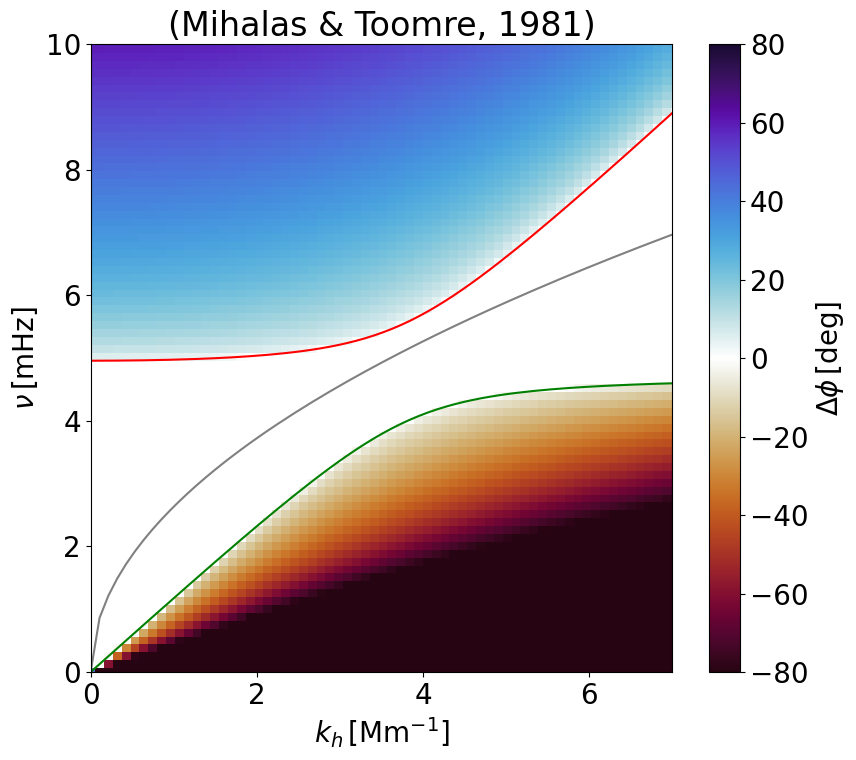

In [3]:
# Create wavenumber and nu grids
kx = np.linspace(1e-10, 15, 200)*1e-3  # Km^-1
ky = np.linspace(1e-10, 15, 200)*1e-3  # Km^-1
kh = np.sqrt(kx**2 + ky**2)  # Km^-1
omega = np.linspace(1e-10, 25, 200)*2*np.pi*1e-3 # mHz

# Use same constants as @vesaMultiheightObservationsAtmospheric2023 Figure 3
wac = .03116156648591974#5.3e-3*2*np.pi # Hz
cs = 7.821691#7 # km/s
g = 0.274 # km/s^2
H = 125.50221125010206435 # km
gamma = 5/3
N = np.sqrt((gamma - 1)*g/(gamma*H))#0.030957466913667436#np.sqrt((gamma - 1)*g**2/cs**2) # Hz
tau = 200  # s
B = 1_500.0 # Gauss
epsilon = 0.0
rho0 = 1e-6 # g/cm^3
dz = 150 # km
model = 'mt1981'

c_alf = B/(np.sqrt(4*np.pi*rho0)) # km/s

# Initialize the class
dd = DiagnosticDiagram(kx, ky, omega, wac, cs, g, N, H, gamma, tau, B, epsilon, rho0, dz)

# Calculate the diagnostic diagram and plot
delta_phi = dd.diagnostic_diagram(model = model)
dd.plot_diagnostic_diagram(model = model)